In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Exercício 1

1. Gere uma amostra de tamanho $K$ de uma variável com distribuição binomial negativa com parâmetros $p$ $r$ utilizando os três métodos vistos em sala: via Bernoullis, via soma de geométricas, via recursão.
2. Compare com uma amostra gerada pelo numpy usando histogramas.
3. Compare o tempo dos três métodos como visto nos labs anteriores.



18


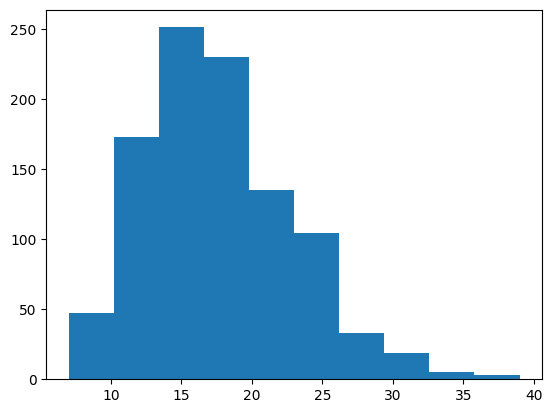

In [ ]:
# Via bernoullis
p = 0.4
r = 7
s = 0
n = 0
while s < r:
  uniform = np.random.uniform(0,1,1)
  B = 0
  for numero in uniform:
    if numero >= p:
      B = 0
    else:
      B = 1
  n += 1
  if B == 1:
    s += 1
print(n)

#Via soma de geométricas
amostra_gem = []
N = 1000
for i in range(N):
  r = 7
  p = 0.4
  bn = []
  for i in range(r):
    u = np.random.uniform()
    num = np.log(1-u)
    den = np.log(1-p)
    x = np.ceil(num/den)
    bn.append(x)
  amostra_gem.append(np.sum(bn))


# Via recursiva
N = 1000
amostra_rec = []
for i in range(N):
  u = np.random.uniform(0, 1)
  r = 7
  n = r
  p = 0.4
  pn = p**r
  F = pn
  while u > F:
    pn = pn * (n*(1-p)/(n - r + 1))
    n += 1
    F += pn
  amostra_rec.append(n)

plt.hist(amostra_rec)

amostra_4 = np.random.negative_binomial(20, 0.4, 1000)

# Exercício 2

1.  Gere uma amostra de tamanho $K$ de uma variável aleatória com distribuição hipergeométrica com parâmetros $M,N,n$ utilizando o método de embaralhamento de Fisher–Yates.
2.  No método de Fisher-Yates, no passo (a), a gente amostra um ponto para troca entre $i$ e $N$. Pense em qual seria o problema caso a gente sempre amostrasse entre $1$ e $N$. Compare o resultado final usando essas duas versões e uma amostra gerada pelo numpy.

In [ ]:
A = [1]
B = [0]

lista = 6*A + 4*B
print(lista)

def embaralhamento(lista):
  for i in range(len(lista)):
    u = np.random.uniform(0,1)
    valor = int(np.floor(u*len(lista)))
    aux1 = lista[i]
    aux2 = lista[valor]
    lista[valor] = aux1
    lista[i] = aux2
  return lista

embaralhamento(lista)






[1, 1, 1, 1, 1, 1, 0, 0, 0, 0]


[1, 0, 0, 1, 0, 1, 1, 0, 1, 1]

# Exercício 3

É intuitivo esperar que, quando o tamanho total da população $M+N$ cresce muito em relação ao tamanho da amostra $n$, o fato de a amostragem ser feita sem reposição passe a ter pouca importância, pois retirar um elemento altera muito pouco a composição da população restante. Nesse caso, cada retirada deve se comportar aproximadamente como um ensaio de Bernoulli independente, com probabilidade de sucesso

$$
p=\frac{N}{M+N}.
$$

Assim, esperamos que a distribuição hipergeométrica com parâmetros $M,N,n$ se aproxime de uma distribuição binomial com parâmetros $n$ e $p$.

Compare numericamente essas duas distribuições para valores crescentes de $M$ e $N$, mantendo aproximadamente constante a proporção

$$
\frac{N}{M+N}\to p,
$$

e mantendo $n$ fixo. Verifique, por meio de simulações, se a aproximação pela distribuição binomial melhora à medida que $M+N$ aumenta.
